# Program 10: membership inference attack (MIA)

**What:** build a simple attack that guesses whether an image was in the training set.

**How:** use the model's loss and confidence as features. Train a logistic regression to tell training images (label 1) from test images (label 0). Then apply it to the forgotten class: a score near 50% means the model looks like it never saw that data.

**Why:** low forget accuracy does not prove the data is gone. MIA is the standard privacy check, and UnCLe reports it.

**Understanding note:** accuracy is what the model *says*, while MIA probes what it *remembers*. Hold on to this idea, because program 14 extends it to the features.

**Done when:** MIA is high on the original model's class 3, and closer to 50% on the retrain model and after BadTeacher.

## Where this fits (for a first-time reader)

Programs 07–09 judged unlearning by **accuracy**: FA (accuracy on cats) should drop, RA (accuracy on the other 9 classes) should stay. But a model can get cats wrong and still carry traces of the exact cat photos it was trained on. Privacy laws ask for the data to be gone, not just for the answers to change.

**The leak an attacker uses.** Every trained network behaves a little differently on images it trained on than on new ones: lower loss, higher confidence. Program 01's model shows this clearly. It is close to 100% right on its training images, but 93.6% on test images. An attacker who sees only the model's outputs can exploit this gap:

> "This image gets a very low loss, so it was probably in the training set."

That is a **membership inference attack (MIA)**. If, after unlearning, the attacker can still tell *training* cats from *unseen* cats, the cat training data has left a trace.

**The models we attack** (each loaded alone, measured, then deleted, to save memory):

| Model | Saw the cat training images? | What we expect |
|---|---|---|
| original (01) | yes | the attack works on cats |
| retrain (07) | **never**: the ideal | training cats look like unseen cats (about 50%) |
| BadTeacher (09) | yes, then unlearned | ? the question of this program |

Program 08's random-labels model was not saved, so it is not attacked here. Section 9 explains how to add it.

Terms: **member** = an image in the model's training set. **Non-member** = an image the model never trained on (here, test images). **Loss** = $-\log p(\text{true class})$, small when the model is confident and right.

## 1. Setup

- `retain_members`: how many retain *training* images (the 9 kept classes) are used as members. 9,000 matches the 9,000 retain *test* images, so the attack sees equal numbers of both.
- `features`: what the attacker reads from each image's output (explained in section 3).
- `forget_repeats` and `cv_folds`: settings for attack 2 (section 5).

Memory: no worker processes, one model on the GPU at a time, and only small arrays of numbers are kept.

In [9]:
import gc, sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # lets us import common/

# Reload the shared code, so edits to common/ are picked up even without restarting the kernel.
import importlib
import common.utils, common.data, common.models, common.train
for module in (common.utils, common.data, common.models, common.train):
    importlib.reload(module)

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from common.data import get_cifar10_unlearning_loaders
from common.models import resnet18_cifar
from common.utils import RESULTS_DIR, get_device, log_run, set_seed

SETTINGS = {
    "forget_class": 3,          # cat
    "seed": 0,
    "retain_members": 9000,     # retain training images used as members (= number of retain test images)
    "features": ["log_loss", "confidence", "entropy"],   # what the attacker reads (section 3)
    "forget_repeats": 10,       # attack 2: random draws of 1,000 training cats
    "cv_folds": 5,              # attack 2: cross-validation folds
}

# The models to attack: name -> file in results/. Missing files are skipped.
MODELS = {
    "original (01)": "01_resnet18_cifar10.pt",
    "retrain (07)": "retrain_model.pt",
    "BadTeacher (09)": "09_badteacher_model.pt",
}

FORGET = SETTINGS["forget_class"]
set_seed(SETTINGS["seed"])
rng = np.random.RandomState(SETTINGS["seed"])
device = get_device()
print("device:", device)

device: cuda


## 2. The four groups of images

Every model is measured on the same four groups. All images are **without augmentation** (no random crop or flip), because the attacker queries the model with the plain image.

| Group | Images | Role |
|---|---|---|
| `retain_train` | 9,000 random training images of the 9 kept classes | members: train attack 1 |
| `retain_test` | all 9,000 test images of the 9 kept classes | non-members: train attack 1 |
| `forget_train` | all 5,000 training cats | **the data we asked the model to forget** |
| `forget_test` | all 1,000 test cats | cats no model has ever trained on |

The key comparison is `forget_train` vs `forget_test`. Both are cats, so any difference the attacker finds between them can only come from training on the first group.

All 24,000 images go into GPU memory once (about 300 MB), as in programs 08 and 09.

In [10]:
loaders = get_cifar10_unlearning_loaders(FORGET, batch_size=128, num_workers=0)
classes = loaders["classes"]


def to_gpu(dataset, indices=None):
    # Load images one by one in the main process (no worker processes), stack, move to GPU.
    idx = range(len(dataset)) if indices is None else indices
    xs, ys = zip(*(dataset[i] for i in idx))
    return torch.stack(xs).to(device), torch.tensor(ys, device=device)


retain_train_ds = loaders["train_retain_plain"].dataset
pick = rng.choice(len(retain_train_ds), SETTINGS["retain_members"], replace=False)
GROUPS = {
    "retain_train": to_gpu(retain_train_ds, pick.tolist()),
    "retain_test": to_gpu(loaders["test_retain"].dataset),
    "forget_train": to_gpu(loaders["train_forget_plain"].dataset),
    "forget_test": to_gpu(loaders["test_forget"].dataset),
}
del loaders, retain_train_ds
gc.collect()

for name, (X, Y) in GROUPS.items():
    print(f"{name:>13}: {len(X):5d} images")

 retain_train:  9000 images
  retain_test:  9000 images
 forget_train:  5000 images
  forget_test:  1000 images


## 3. What the attacker sees

The attacker can only query the model and read its output probabilities (a "black-box" attack). From each image's output it computes three numbers:

| Feature | Formula | Members usually have... |
|---|---|---|
| `log_loss` | $\log\big(-\log p(\text{true class})\big)$ | lower loss |
| `confidence` | the highest probability, $\max_c p(c)$ | higher confidence |
| `entropy` | $-\sum_c p(c)\log p(c)$: how spread out the answer is | lower entropy |

We take the log of the loss because training losses are tiny (often below 0.001), and the log spreads those small values out so the attack can tell them apart.

Note: the loss needs the true label. That is a standard assumption in MIA papers: the attacker holds a photo and knows what it shows, and wants to know if *that photo* was used for training.

The cell below runs each model once on all four groups, keeps only these numbers, and frees the model. It also prints accuracy and average loss per group: **the gap between `train` and `test` columns is exactly what the attack will try to exploit.**

In [11]:
@torch.no_grad()
def logits_of(model, X, chunk=1000):
    model.eval()
    return torch.cat([model(X[i:i + chunk]) for i in range(0, len(X), chunk)])


def features_of(model, X, Y):
    # Per image: loss on the true label, top confidence, entropy, and whether the answer was right.
    logp = F.log_softmax(logits_of(model, X).float(), dim=1)
    p = logp.exp()
    return {
        "loss": (-logp.gather(1, Y[:, None]).squeeze(1)).cpu().numpy(),
        "confidence": p.max(1).values.cpu().numpy(),
        "entropy": (-(p * logp).sum(1)).cpu().numpy(),
        "correct": (logp.argmax(1) == Y).cpu().numpy(),
    }


def free_gpu():
    gc.collect()
    torch.cuda.empty_cache()


feats = {}   # model name -> group name -> features
for name, file in MODELS.items():
    path = RESULTS_DIR / file
    if not path.exists():
        print(f"{name}: {path.name} not found, skipped (run that program first)")
        continue
    model = resnet18_cifar(num_classes=10).to(device)
    model.load_state_dict(torch.load(path, map_location=device))
    feats[name] = {g: features_of(model, X, Y) for g, (X, Y) in GROUPS.items()}
    del model
    free_gpu()

print(f"\n{'model':>16} | {'accuracy':^29} | {'average loss':^33}")
print(f"{'':>16} | {'retain':^13} {'cat':^15} | {'retain':^15} {'cat':^17}")
print(f"{'':>16} | {'train':>6} {'test':>6} {'train':>7} {'test':>7} | {'train':>7} {'test':>7} {'train':>8} {'test':>8}")
for name, f in feats.items():
    acc = {g: f[g]["correct"].mean() * 100 for g in GROUPS}
    loss = {g: f[g]["loss"].mean() for g in GROUPS}
    print(f"{name:>16} | {acc['retain_train']:5.1f}% {acc['retain_test']:5.1f}% {acc['forget_train']:6.1f}% {acc['forget_test']:6.1f}% | "
          f"{loss['retain_train']:7.3f} {loss['retain_test']:7.3f} {loss['forget_train']:8.3f} {loss['forget_test']:8.3f}")


           model |           accuracy            |           average loss           
                 |    retain           cat       |     retain             cat       
                 |  train   test   train    test |   train    test    train     test
   original (01) |  99.7%  94.5%   99.1%   85.7% |   0.013   0.190    0.037    0.441
    retrain (07) |  99.8%  94.9%    0.0%    0.0% |   0.009   0.173   10.878   10.804
 BadTeacher (09) |  99.4%  94.7%    3.2%    1.9% |   0.028   0.189    1.891    2.264


## 4. Look before attacking: loss of training cats vs unseen cats

Each panel shows, for one model, the loss on the 5,000 **training** cats and on the 1,000 **unseen test** cats (log scale, each histogram normalized to area 1, so the different group sizes don't matter).

- If the two histograms **overlap**, no attacker can tell them apart from the loss alone.
- If the training cats sit **further left** (lower loss), the model still remembers them.

Expect the original model to separate them, and the retrain model to overlap them (it never saw either group). For BadTeacher, look closely: it trained on the training cats (pushing them towards the bad teacher's answers) but never on the test cats. Does that leave its own, different trace?

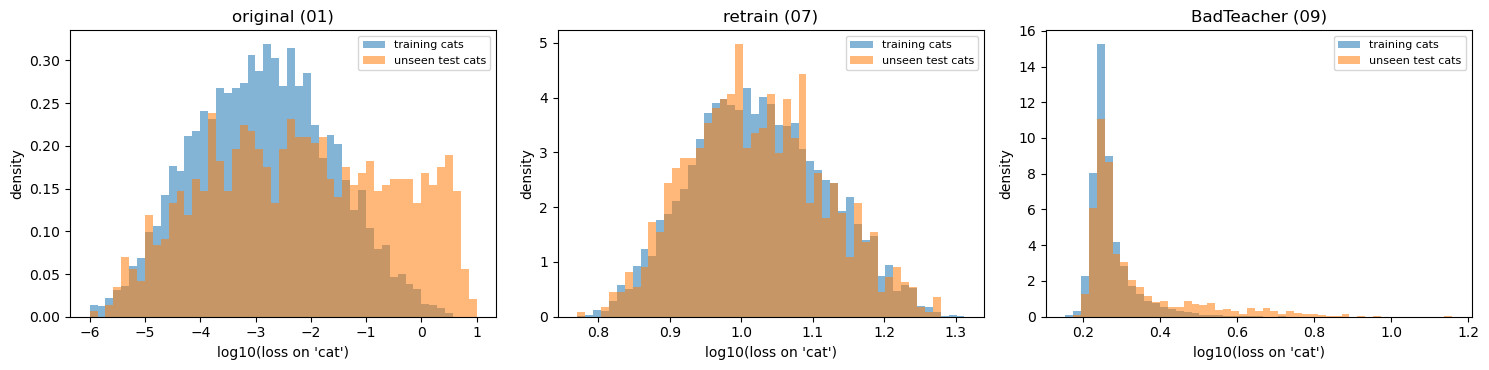

In [12]:
fig, axes = plt.subplots(1, len(feats), figsize=(5 * len(feats), 3.8), squeeze=False)
for ax, (name, f) in zip(axes[0], feats.items()):
    lo = np.log10(np.clip(np.concatenate([f["forget_train"]["loss"], f["forget_test"]["loss"]]), 1e-6, None))
    bins = np.linspace(lo.min(), lo.max(), 50)
    for g, label in [("forget_train", "training cats"), ("forget_test", "unseen test cats")]:
        ax.hist(np.log10(np.clip(f[g]["loss"], 1e-6, None)), bins=bins, density=True, alpha=0.55, label=label)
    ax.set(title=name, xlabel="log10(loss on 'cat')", ylabel="density")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "10_cat_loss_hist.png", dpi=120)
plt.show()

## 5. Two attacks

### Attack 1: the roadmap's attack (general "was this image trained on?")

For each model separately:
1. Train a logistic regression on the 3 features: retain **training** images = 1, retain **test** images = 0. Half of each group trains the attack, the other half checks it. The check accuracy is how much the model **leaks in general** (50% = no leak).
2. Apply that attack to the cats and report the **member rate**: the share of images it calls "member". Do this both for training cats and for unseen test cats.

How to read it: a model that remembers its training cats gives them a **higher** member rate than the unseen cats. A model that has forgotten them gives both groups about the same rate.

Warning: the member rate of training cats is **not** supposed to be 50%. Cats are wrong and high-loss for an unlearned model, so the attack calls almost all of them non-members, even for the retrain model. The right target is **the retrain model's numbers**, not a fixed value. (Papers that report "MIA-efficacy" use exactly this attack and compare against retrain.)

### Attack 2: training cats vs unseen cats (the sharp test, where 50% is the target)

Attack 1 learns what members look like from *other* classes, and that may not transfer to cats. Attack 2 asks the question directly. It trains a logistic regression on the **cats themselves**: 1,000 training cats (label 1) vs the 1,000 test cats (label 0), and reports cross-validated accuracy (train on 4/5, test on the remaining 1/5, rotate).

- 50% = the attacker cannot tell training cats from unseen cats: the model looks like it never saw them.
- Above 50% = something about the training cats is still visible.

We repeat it with 10 different random draws of 1,000 training cats (out of 5,000) and report mean ± spread. Each check uses only 400 images, so expect about ±2–3% of noise even for a perfect model: **differences under about 3 points are not meaningful.**

In [13]:
FEATURE_FNS = {
    "log_loss": lambda f: np.log(np.clip(f["loss"], 1e-6, None)),
    "confidence": lambda f: f["confidence"],
    "entropy": lambda f: f["entropy"],
}


def attack_matrix(f):
    # One row per image, one column per feature chosen in SETTINGS.
    return np.stack([FEATURE_FNS[k](f) for k in SETTINGS["features"]], axis=1)


def make_attack():
    # Scale each feature to mean 0 / std 1, then logistic regression.
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))


def attack1(f):
    Xm, Xn = attack_matrix(f["retain_train"]), attack_matrix(f["retain_test"])
    pm, pn = rng.permutation(len(Xm)), rng.permutation(len(Xn))
    hm, hn = len(Xm) // 2, len(Xn) // 2
    X_fit = np.concatenate([Xm[pm[:hm]], Xn[pn[:hn]]])
    y_fit = np.r_[np.ones(hm), np.zeros(hn)]
    X_chk = np.concatenate([Xm[pm[hm:]], Xn[pn[hn:]]])
    y_chk = np.r_[np.ones(len(Xm) - hm), np.zeros(len(Xn) - hn)]
    clf = make_attack().fit(X_fit, y_fit)
    return {
        "retain_attack_acc": clf.score(X_chk, y_chk),
        "member_rate_train_cats": clf.predict(attack_matrix(f["forget_train"])).mean(),
        "member_rate_test_cats": clf.predict(attack_matrix(f["forget_test"])).mean(),
    }


def attack2(f):
    X_tr, X_te = attack_matrix(f["forget_train"]), attack_matrix(f["forget_test"])
    scores = []
    for _ in range(SETTINGS["forget_repeats"]):
        pick = rng.choice(len(X_tr), len(X_te), replace=False)       # 1,000 of the 5,000 training cats
        X = np.concatenate([X_tr[pick], X_te])
        y = np.r_[np.ones(len(X_te)), np.zeros(len(X_te))]
        cv = StratifiedKFold(SETTINGS["cv_folds"], shuffle=True, random_state=int(rng.randint(10**6)))
        scores.extend(cross_val_score(make_attack(), X, y, cv=cv))
    return {"forget_attack_acc": float(np.mean(scores)), "forget_attack_std": float(np.std(scores))}


mia = {name: {**attack1(f), **attack2(f)} for name, f in feats.items()}

print(f"{'model':>16} | {'attack 1':^40} | {'attack 2':^16}")
print(f"{'':>16} | {'leak on retain':>14} {'member rate: train cats':>24} | {'train vs test':>16}")
print(f"{'':>16} | {'':>14} {'train cats':>11} {'test cats':>10}   | {'cats (50% = ideal)':>16}")
for name, r in mia.items():
    print(f"{name:>16} | {r['retain_attack_acc']*100:13.1f}% {r['member_rate_train_cats']*100:10.1f}% "
          f"{r['member_rate_test_cats']*100:9.1f}%   | {r['forget_attack_acc']*100:7.1f}% ± {r['forget_attack_std']*100:.1f}")

           model |                 attack 1                 |     attack 2    
                 | leak on retain  member rate: train cats |    train vs test
                 |                 train cats  test cats   | cats (50% = ideal)
   original (01) |          54.9%       77.7%      58.0%   |    60.6% ± 2.1
    retrain (07) |          54.7%        0.0%       0.0%   |    49.9% ± 2.6
 BadTeacher (09) |          54.7%        0.0%       0.0%   |    58.4% ± 2.4


## 6. The picture

Left: attack 2 accuracy for each model, with the 50% line (cannot tell) and the retrain model's value (the ideal). Right: attack 1's member rate for training cats vs unseen cats. For a model that has forgotten, the two bars should be about the same height and match the retrain model's bars.

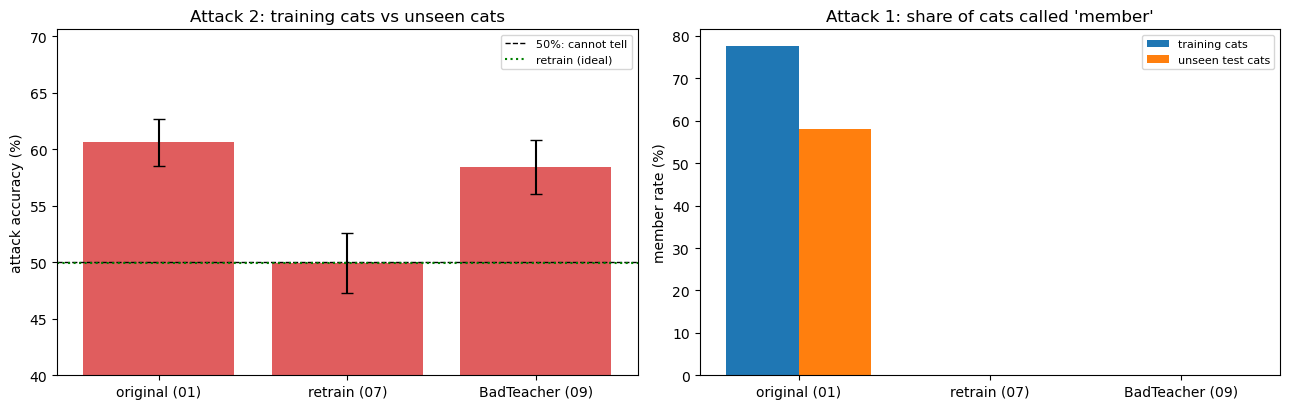

In [14]:
names = list(mia)
x = np.arange(len(names))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

ax = axes[0]
acc2 = [mia[n]["forget_attack_acc"] * 100 for n in names]
err2 = [mia[n]["forget_attack_std"] * 100 for n in names]
ax.bar(x, acc2, yerr=err2, capsize=4, color="tab:red", alpha=0.75)
ax.axhline(50, color="black", ls="--", lw=1, label="50%: cannot tell")
if "retrain (07)" in mia:
    ax.axhline(mia["retrain (07)"]["forget_attack_acc"] * 100, color="green", ls=":", lw=1.5, label="retrain (ideal)")
ax.set_xticks(x, names)
ax.set(title="Attack 2: training cats vs unseen cats", ylabel="attack accuracy (%)", ylim=(40, max(acc2) + 10))
ax.legend(fontsize=8)

ax = axes[1]
w = 0.38
ax.bar(x - w / 2, [mia[n]["member_rate_train_cats"] * 100 for n in names], w, label="training cats")
ax.bar(x + w / 2, [mia[n]["member_rate_test_cats"] * 100 for n in names], w, label="unseen test cats")
ax.set_xticks(x, names)
ax.set(title="Attack 1: share of cats called 'member'", ylabel="member rate (%)")
ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig(RESULTS_DIR / "10_mia.png", dpi=120)
plt.show()

## 7. Which feature gives it away?

For each model and each feature, the average value on training cats vs unseen cats. A clear difference in any row is a trace of the training cats.

This helps explain attack 2's result. For example, if BadTeacher's training cats have lower **entropy** than its test cats, that is because the student was pushed to copy the bad teacher's answers on exactly those images (and the bad teacher gives almost every image the same answer). The *unlearning itself* would then leave the trace. Papers call this the "Streisand effect": trying to hide something makes it stand out.

In [15]:
print(f"{'model':>16} {'feature':>11} {'training cats':>14} {'unseen cats':>12}")
for name, f in feats.items():
    for k in ["loss", "confidence", "entropy"]:
        print(f"{name:>16} {k:>11} {f['forget_train'][k].mean():14.4f} {f['forget_test'][k].mean():12.4f}")
    print()

           model     feature  training cats  unseen cats
   original (01)        loss         0.0367       0.4406
   original (01)  confidence         0.9760       0.9183
   original (01)     entropy         0.0828       0.2219

    retrain (07)        loss        10.8776      10.8035
    retrain (07)  confidence         0.8461       0.8363
    retrain (07)     entropy         0.4219       0.4408

 BadTeacher (09)        loss         1.8910       2.2638
 BadTeacher (09)  confidence         0.2616       0.3340
 BadTeacher (09)     entropy         2.0445       1.8800



## 8. Log the run, then free memory

In [16]:
log_run("10_mia", SETTINGS,
        {name: {"accuracy": {g: round(float(f[g]["correct"].mean()), 4) for g in GROUPS},
                "mean_loss": {g: round(float(f[g]["loss"].mean()), 4) for g in GROUPS},
                **{k: round(float(v), 4) for k, v in mia[name].items()}}
         for name, f in feats.items()})
print("logged to", RESULTS_DIR / "runs.jsonl")

del GROUPS
free_gpu()

logged to /run/media/adarsh/AAE039EFE039C1FD/std/research/results/runs.jsonl


## 9. Optional: change the settings

Change a value in section 1 and run again from the top (each run takes about a minute). Every run is logged.
- `features` = `["log_loss"]`: the loss alone. How much weaker is the attack? If BadTeacher is caught only with `entropy`, the trace comes from *how* it answers, not *whether* it is right.
- `features` = `["confidence", "entropy"]`: no true label needed (a weaker attacker who doesn't know the image shows a cat).
- `seed` 1: different random draws. Do the numbers move by more than the ±2–3% noise?
- **Attack program 08's random-labels model:** in program 08, after the RL loop, add `torch.save(model.state_dict(), RESULTS_DIR / "08_rl_model.pt")` (use that notebook's name for the RL model), run it, then add `"random labels (08)": "08_rl_model.pt"` to `MODELS` here. Its cat confidence was very low (29% vs the retrain model's 84%): does attack 2 notice?
- **Stronger attacks** exist: shadow models (train copies of the model to learn what members look like) and LiRA. This simple attack gives a *lower bound* on the leak. If it already finds something, a stronger one will find more.

## Lab notebook

*Write one paragraph here: what you saw, and what surprised you.*

Questions to answer in it:
1. How big is the original model's train/test gap (section 3), and did attack 1 detect a general leak (above 50% on retain)?
2. Attack 2 on the original model: how far above 50%? Is cat (the weakest class) easier to attack than you expected?
3. Attack 2 on the retrain model: close to 50%? It should be, because it never saw either group of cats. If not, what else could separate training cats from test cats?
4. BadTeacher: FA was low in program 09. Is attack 2 also near the retrain model's value, or does the unlearning leave its own trace? Which feature in section 7 gives it away?
5. Attack 1's member rate on cats: why is it *not* 50% for the retrain model, and why is "same as retrain" the right target instead?
6. Accuracy is what the model *says*, MIA is what its *outputs* reveal. Neither looks inside the network. Could the cat features still be in the hidden layers even if both are perfect? (Program 14 tests this.)